<a href="https://colab.research.google.com/github/uzmaa29/deeplearning/blob/main/regularizatn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# regularization techniques
exploring baseline performance, L1/L2 regularization, dropout, batch normalization, and early stopping with keras.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.regularizers import l1, l2
from tensorflow.keras.callbacks import EarlyStopping

np.random.seed(42)
tf.random.set_seed(42)

In [ ]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

X_train = X_train.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)

X_val = X_train[-10000:]
y_val = y_train[-10000:]
X_train = X_train[:-10000]
y_train = y_train[:-10000]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training: (50000, 784)
Validation: (10000, 784)
Testing: (10000, 784)


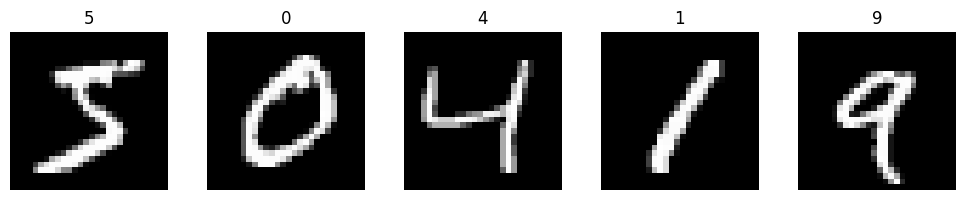

In [ ]:
plt.figure(figsize=(10, 2))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap="gray")
    plt.title(y_train[i])
    plt.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
def create_baseline():
    model = Sequential([
        Dense(512, activation="relu", input_shape=(784,)),
        Dense(256, activation="relu"),
        Dense(128, activation="relu"),
        Dense(10, activation="softmax")
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

baseline_model = create_baseline()
baseline_history = baseline_model.fit(
    X_train, y_train, epochs=20, batch_size=128,
    validation_data=(X_val, y_val), verbose=1
)

baseline_test_loss, baseline_test_accuracy = baseline_model.evaluate(X_test, y_test, verbose=0)
print("Baseline Test Accuracy:", baseline_test_accuracy)
print("Baseline Test Loss:", baseline_test_loss)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.9227 - loss: 0.2568 - val_accuracy: 0.9676 - val_loss: 0.1094
Epoch 2/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.9734 - loss: 0.0911 - val_accuracy: 0.9667 - val_loss: 0.1100
Epoch 3/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9824 - loss: 0.0588 - val_accuracy: 0.9681 - val_loss: 0.1090
Epoch 4/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.9872 - loss: 0.0417 - val_accuracy: 0.9701 - val_loss: 0.1097
Epoch 5/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9884 - loss: 0.0353 - val_accuracy: 0.9719 - val_loss: 0.1074
Epoch 6/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.9907 - loss: 0.0272 - val_accuracy: 0.9756 - val_loss: 0.0947
Epoch 7/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9926 - loss: 0.0217 - val_accuracy: 0.9793 - val_loss: 0.0901
Epoch 8/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 12s 20ms/step - accuracy: 0.9946 - loss: 0.0166 - val_acc

In [ ]:
def create_l1_model():
    model = Sequential([
        Dense(512, activation="relu", kernel_regularizer=l1(0.0001), input_shape=(784,)),
        Dense(256, activation="relu", kernel_regularizer=l1(0.0001)),
        Dense(128, activation="relu", kernel_regularizer=l1(0.0001)),
        Dense(10, activation="softmax")
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

l1_model = create_l1_model()
l1_history = l1_model.fit(
    X_train, y_train, epochs=20, batch_size=128,
    validation_data=(X_val, y_val), verbose=1
)
l1_test_loss, l1_test_accuracy = l1_model.evaluate(X_test, y_test, verbose=0)
print("L1 Test Accuracy:", l1_test_accuracy)
print("L1 Test Loss:", l1_test_loss)

Epoch 1/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.9186 - loss: 1.2751 - val_accuracy: 0.9490 - val_loss: 0.8142
Epoch 2/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.9574 - loss: 0.6566 - val_accuracy: 0.9637 - val_loss: 0.5320
Epoch 3/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.9660 - loss: 0.4668 - val_accuracy: 0.9735 - val_loss: 0.3931
Epoch 4/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.9718 - loss: 0.3631 - val_accuracy: 0.9752 - val_loss: 0.3207
Epoch 5/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.9759 - loss: 0.3001 - val_accuracy: 0.9746 - val_loss: 0.2843
Epoch 6/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.9789 - loss: 0.2620 - val_accuracy: 0.9753 - val_loss: 0.2629
Epoch 7/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.9809 - loss: 0.2372 - val_accuracy: 0.9743 - val_loss: 0.2522
Epoch 8/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.9820 - loss: 0.2205 - val_accu

In [ ]:
def create_l2_model():
    model = Sequential([
        Dense(512, activation="relu", kernel_regularizer=l2(0.0001), input_shape=(784,)),
        Dense(256, activation="relu", kernel_regularizer=l2(0.0001)),
        Dense(128, activation="relu", kernel_regularizer=l2(0.0001)),
        Dense(10, activation="softmax")
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

l2_model = create_l2_model()
l2_history = l2_model.fit(
    X_train, y_train, epochs=20, batch_size=128,
    validation_data=(X_val, y_val), verbose=1
)
l2_test_loss, l2_test_accuracy = l2_model.evaluate(X_test, y_test, verbose=0)
print("L2 Test Accuracy:", l2_test_accuracy)
print("L2 Test Loss:", l2_test_loss)

Epoch 1/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.9236 - loss: 0.3444 - val_accuracy: 0.9645 - val_loss: 0.2018
Epoch 2/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.9708 - loss: 0.1805 - val_accuracy: 0.9707 - val_loss: 0.1762
Epoch 3/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.9793 - loss: 0.1463 - val_accuracy: 0.9724 - val_loss: 0.1735
Epoch 4/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.9851 - loss: 0.1262 - val_accuracy: 0.9678 - val_loss: 0.1942
Epoch 5/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.9870 - loss: 0.1168 - val_accuracy: 0.9610 - val_loss: 0.2107
Epoch 6/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 9s 16ms/step - accuracy: 0.9881 - loss: 0.1094 - val_accuracy: 0.9730 - val_loss: 0.1662
Epoch 7/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.9902 - loss: 0.1013 - val_accuracy: 0.9690 - val_loss: 0.1822
Epoch 8/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - accuracy: 0.9915 - loss: 0.0950 - val_acc

In [ ]:
def create_dropout_model():
    model = Sequential([
        Dense(512, activation="relu", input_shape=(784,)),
        Dropout(0.3),
        Dense(256, activation="relu"),
        Dropout(0.3),
        Dense(128, activation="relu"),
        Dropout(0.2),
        Dense(10, activation="softmax")
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

dropout_model = create_dropout_model()
dropout_history = dropout_model.fit(
    X_train, y_train, epochs=20, batch_size=128,
    validation_data=(X_val, y_val), verbose=1
)
dropout_test_loss, dropout_test_accuracy = dropout_model.evaluate(X_test, y_test, verbose=0)
print("Dropout Test Accuracy:", dropout_test_accuracy)
print("Dropout Test Loss:", dropout_test_loss)

Epoch 1/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.8867 - loss: 0.3681 - val_accuracy: 0.9615 - val_loss: 0.1327
Epoch 2/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.9546 - loss: 0.1532 - val_accuracy: 0.9705 - val_loss: 0.1023
Epoch 3/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.9673 - loss: 0.1110 - val_accuracy: 0.9741 - val_loss: 0.0888
Epoch 4/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.9715 - loss: 0.0924 - val_accuracy: 0.9751 - val_loss: 0.0841
Epoch 5/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.9762 - loss: 0.0794 - val_accuracy: 0.9779 - val_loss: 0.0779
Epoch 6/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.9788 - loss: 0.0657 - val_accuracy: 0.9779 - val_loss: 0.0839
Epoch 7/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.9818 - loss: 0.0592 - val_accuracy: 0.9781 - val_loss: 0.0818
Epoch 8/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - accuracy: 0.9824 - loss: 0.0536 - val_ac

In [ ]:
def create_batchnorm_model():
    model = Sequential([
        Dense(512, activation="relu", input_shape=(784,)),
        BatchNormalization(),
        Dense(256, activation="relu"),
        BatchNormalization(),
        Dense(128, activation="relu"),
        BatchNormalization(),
        Dense(10, activation="softmax")
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

batchnorm_model = create_batchnorm_model()
batchnorm_history = batchnorm_model.fit(
    X_train, y_train, epochs=20, batch_size=128,
    validation_data=(X_val, y_val), verbose=1
)
batchnorm_test_loss, batchnorm_test_accuracy = batchnorm_model.evaluate(X_test, y_test, verbose=0)
print("Batch Normalization Test Accuracy:", batchnorm_test_accuracy)
print("Batch Normalization Test Loss:", batchnorm_test_loss)

Epoch 1/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - accuracy: 0.9421 - loss: 0.1899 - val_accuracy: 0.9675 - val_loss: 0.1119
Epoch 2/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - accuracy: 0.9787 - loss: 0.0689 - val_accuracy: 0.9696 - val_loss: 0.1022
Epoch 3/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.9897 - loss: 0.0357 - val_accuracy: 0.9705 - val_loss: 0.1032
Epoch 4/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.9916 - loss: 0.0276 - val_accuracy: 0.9742 - val_loss: 0.1004
Epoch 5/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.9910 - loss: 0.0274 - val_accuracy: 0.9734 - val_loss: 0.1005
Epoch 6/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.9931 - loss: 0.0205 - val_accuracy: 0.9792 - val_loss: 0.0807
Epoch 7/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.9949 - loss: 0.0156 - val_accuracy: 0.9809 - val_loss: 0.0758
Epoch 8/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.9962 - loss: 0.0122 - val_ac

In [ ]:
def create_earlystop_model():
    model = Sequential([
        Dense(512, activation="relu", input_shape=(784,)),
        Dense(256, activation="relu"),
        Dropout(0.3),
        Dense(128, activation="relu"),
        Dense(10, activation="softmax")
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

earlystop_model = create_earlystop_model()
early_stopping = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

earlystop_history = earlystop_model.fit(
    X_train, y_train, epochs=20, batch_size=128,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping], verbose=1
)
earlystop_test_loss, earlystop_test_accuracy = earlystop_model.evaluate(X_test, y_test, verbose=0)
print("Early Stopping Test Accuracy:", earlystop_test_accuracy)
print("Early Stopping Test Loss:", earlystop_test_loss)
print("Epochs Completed:", len(earlystop_history.history["loss"]))

Epoch 1/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - accuracy: 0.9119 - loss: 0.2889 - val_accuracy: 0.9638 - val_loss: 0.1135
Epoch 2/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.9667 - loss: 0.1083 - val_accuracy: 0.9728 - val_loss: 0.0951
Epoch 3/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.9768 - loss: 0.0726 - val_accuracy: 0.9711 - val_loss: 0.1010
Epoch 4/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.9839 - loss: 0.0513 - val_accuracy: 0.9694 - val_loss: 0.1061
Epoch 5/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.9873 - loss: 0.0394 - val_accuracy: 0.9726 - val_loss: 0.1005
Early Stopping Test Accuracy: 0.9704999923706055
Early Stopping Test Loss: 0.09352859109640121
Epochs Completed: 5


In [ ]:
def create_final_model():
    model = Sequential([
        Dense(512, activation="relu", input_shape=(784,)),
        BatchNormalization(),
        Dropout(0.3),
        Dense(256, activation="relu"),
        BatchNormalization(),
        Dropout(0.3),
        Dense(128, activation="relu"),
        BatchNormalization(),
        Dense(10, activation="softmax")
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

final_model = create_final_model()
final_early_stopping = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

final_history = final_model.fit(
    X_train, y_train, epochs=20, batch_size=128,
    validation_data=(X_val, y_val),
    callbacks=[final_early_stopping], verbose=1
)
final_test_loss, final_test_accuracy = final_model.evaluate(X_test, y_test, verbose=0)

print("Final Model Test Accuracy:", final_test_accuracy)
print("Final Model Test Loss:", final_test_loss)
print("Epochs Completed:", len(final_history.history["loss"]))

Epoch 1/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - accuracy: 0.9099 - loss: 0.2922 - val_accuracy: 0.9652 - val_loss: 0.1183
Epoch 2/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.9571 - loss: 0.1346 - val_accuracy: 0.9710 - val_loss: 0.0938
Epoch 3/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.9687 - loss: 0.0999 - val_accuracy: 0.9756 - val_loss: 0.0830
Epoch 4/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.9747 - loss: 0.0821 - val_accuracy: 0.9773 - val_loss: 0.0812
Epoch 5/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.9766 - loss: 0.0732 - val_accuracy: 0.9774 - val_loss: 0.0767
Epoch 6/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.9809 - loss: 0.0592 - val_accuracy: 0.9791 - val_loss: 0.0736
Epoch 7/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.9817 - loss: 0.0554 - val_accuracy: 0.9796 - val_loss: 0.0743
Epoch 8/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.9834 - loss: 0.0496 - val_acc

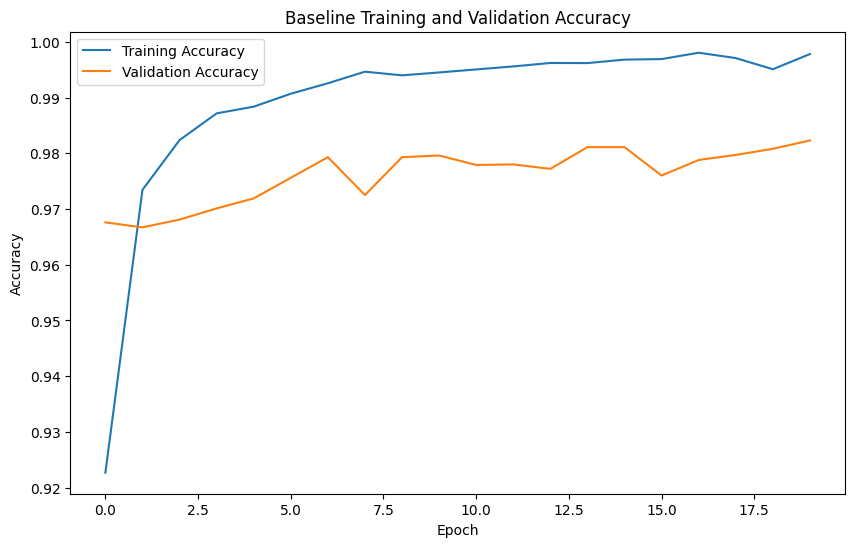

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(baseline_history.history["accuracy"], label="Training Accuracy")
plt.plot(baseline_history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Baseline Training and Validation Accuracy")
plt.legend()
plt.show()

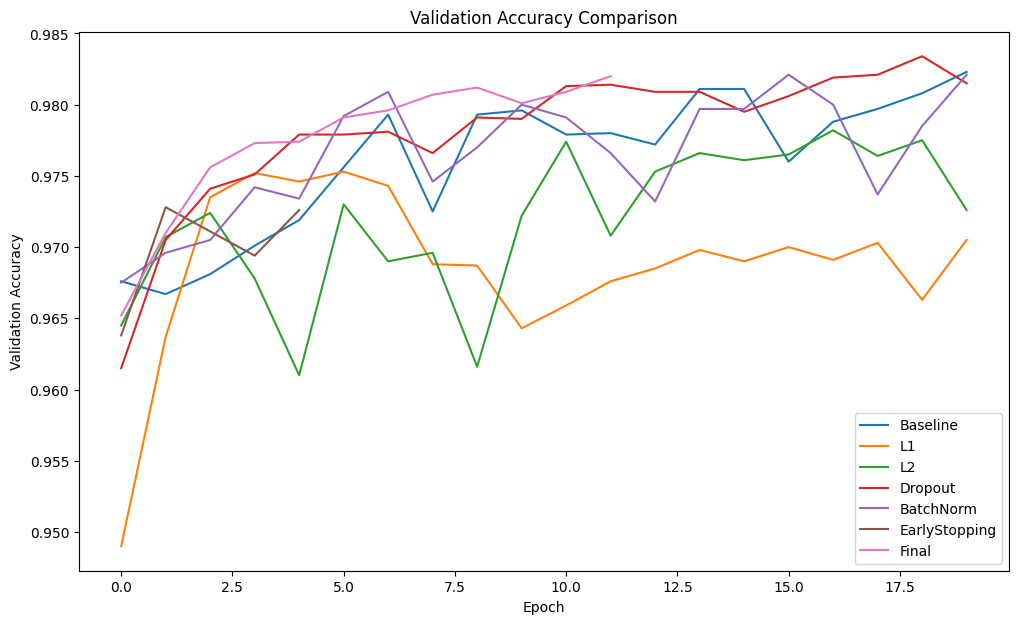

In [ ]:
histories = {
    "Baseline": baseline_history,
    "L1": l1_history,
    "L2": l2_history,
    "Dropout": dropout_history,
    "BatchNorm": batchnorm_history,
    "EarlyStopping": earlystop_history,
    "Final": final_history
}

plt.figure(figsize=(12, 7))
for name, hist in histories.items():
    plt.plot(hist.history["val_accuracy"], label=name)
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy Comparison")
plt.legend()
plt.show()

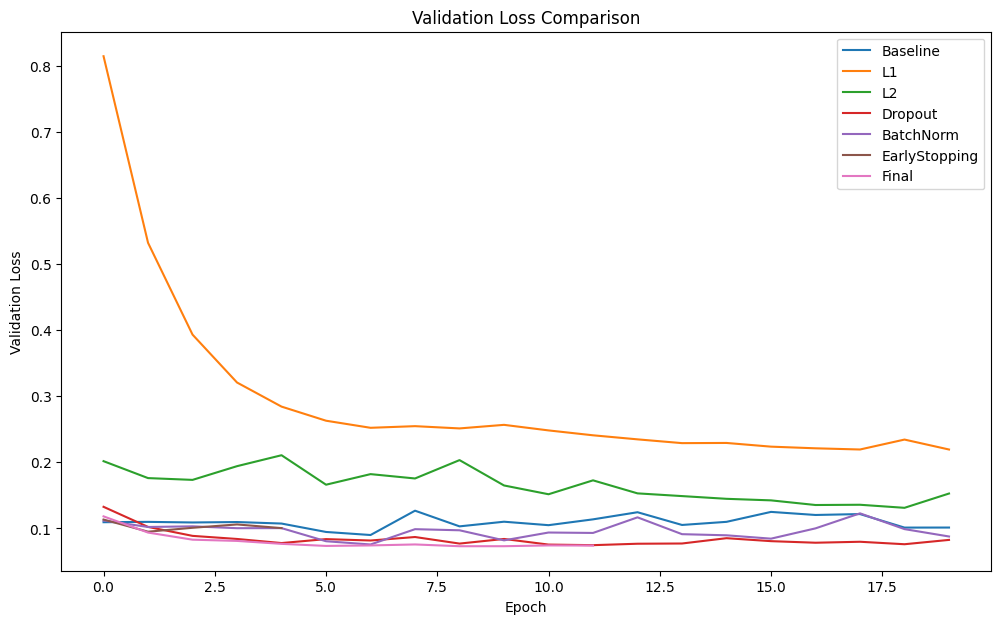

In [ ]:
plt.figure(figsize=(12, 7))
for name, hist in histories.items():
    plt.plot(hist.history["val_loss"], label=name)
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss Comparison")
plt.legend()
plt.show()

In [ ]:
results = pd.DataFrame({
    "Model": [
        "Baseline", "L1 Regularization", "L2 Regularization",
        "Dropout", "Batch Normalization", "Early Stopping", "Final Model"
    ],
    "Test Accuracy": [
        baseline_test_accuracy, l1_test_accuracy, l2_test_accuracy,
        dropout_test_accuracy, batchnorm_test_accuracy,
        earlystop_test_accuracy, final_test_accuracy
    ],
    "Test Loss": [
        baseline_test_loss, l1_test_loss, l2_test_loss,
        dropout_test_loss, batchnorm_test_loss,
        earlystop_test_loss, final_test_loss
    ],
    "Epochs": [
        len(baseline_history.history["loss"]),
        len(l1_history.history["loss"]),
        len(l2_history.history["loss"]),
        len(dropout_history.history["loss"]),
        len(batchnorm_history.history["loss"]),
        len(earlystop_history.history["loss"]),
        len(final_history.history["loss"])
    ]
})

results

,Model,Test Accuracy,Test Loss,Epochs
0,Baseline,0.9820,0.097043,20
1,L1 Regularization,0.9709,0.214849,20
2,L2 Regularization,0.9748,0.150400,20
3,Dropout,0.9830,0.072562,20
4,Batch Normalization,0.9806,0.087284,20
5,Early Stopping,0.9705,0.093529,5
6,Final Model,0.9799,0.066160,12


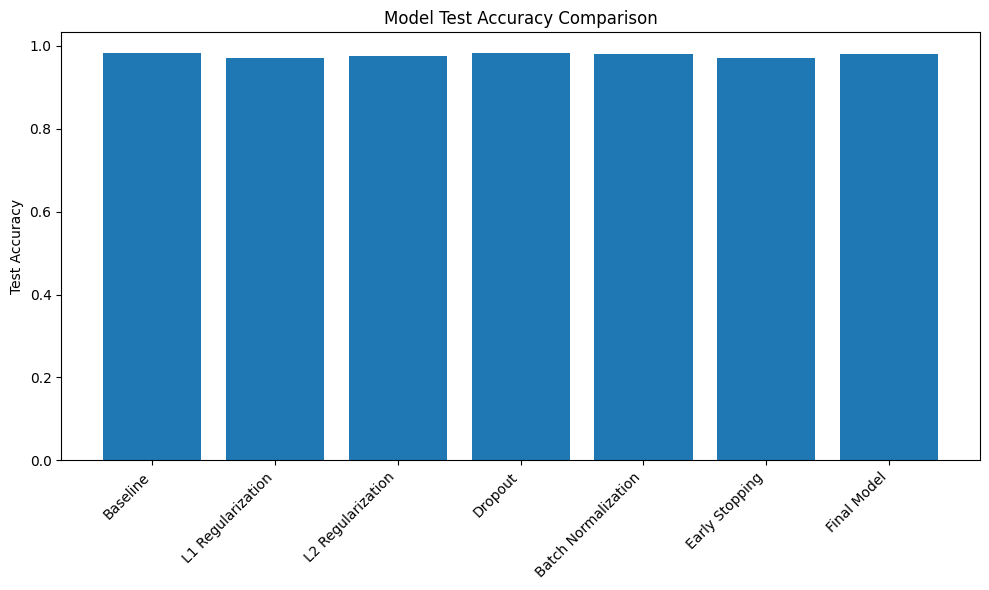

In [ ]:
plt.figure(figsize=(10, 6))
plt.bar(results["Model"], results["Test Accuracy"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Test Accuracy")
plt.title("Model Test Accuracy Comparison")
plt.tight_layout()
plt.show()

In [ ]:
print("final training accuracy:", baseline_history.history["accuracy"][-1])
print("final validation accuracy:", baseline_history.history["val_accuracy"][-1])
print("Final model final training accuracy:", final_history.history["accuracy"][-1])
print("Final model final validation accuracy:", final_history.history["val_accuracy"][-1])

final training accuracy: 0.9977999925613403
final validation accuracy: 0.9822999835014343
Final model final training accuracy: 0.988860011100769
Final model final validation accuracy: 0.9819999933242798
